# 06 · Perfis de retidos com movimentação e proxies observáveis de oferta

**Pergunta do case:** quais atributos em M0 diferenciam movimentação **entre os atendimentos classificados como retidos**? Este notebook expõe métricas **computadas na planilha local** e publicadas somente em agregados de grupos grandes.

A análise de aceite de oferta é **inferencial, não observada**: nenhuma proxy é tratada como rótulo de aceite. População: junho–dezembro de 2025, unidade: registro. Eventos e valores seguem as definições provisórias.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists(): ROOT=ROOT.parent
s=json.loads((ROOT/"reports/retained_profile_study_2025.json").read_text(encoding="utf-8"))
assert "NOT_OBSERVED" in s["definitions"]["offer_acceptance"]
assert s["totals"]["moved"] <= s["totals"]["total"]
print("População retida:",f"{s['totals']['total']:,}")
print("Movimento condicional:",f"{s['rates']['movement_given_retained']:.2%}")
print("Proxy estrita de alteração contratual:",f"{s['rates']['strict_contract_change_proxy_given_retained']:.2%}")

População retida: 249,309
Movimento condicional: 34.71%
Proxy estrita de alteração contratual: 34.71%


## 1. Composição da carteira no início do atendimento

A taxa de alguma movimentação depende da quantidade de famílias elegíveis. Contagens por cliente não são observações independentes; os estratos descritivos devem ser lidos como associações, não como efeitos de oferecer mais produtos.

1 n=90,470 MOV=27.6% proxy restrita=27.6%
2 n=91,072 MOV=36.9% proxy restrita=36.9%
3 n=65,304 MOV=40.3% proxy restrita=40.3%
4 n=2,333 MOV=69.5% proxy restrita=69.5%


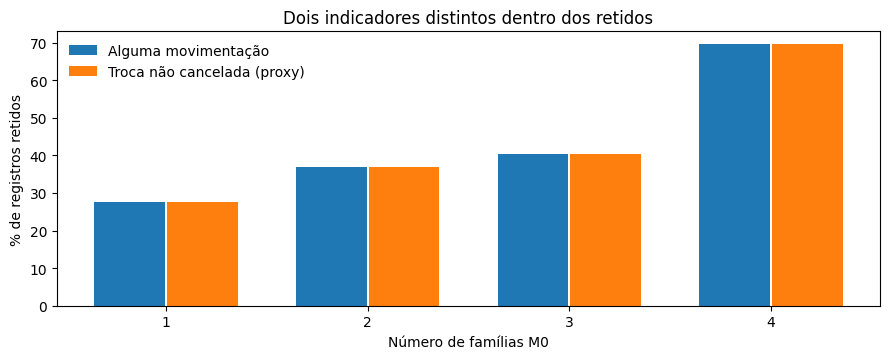

In [2]:
groups = sorted(s["segments"]["family_count_m0"], key=lambda x: int(x["group"]))
labels=[x["group"] for x in groups]
for x in groups: print(x["group"],f"n={x['n']:,}",f"MOV={x['movement_rate']:.1%}",f"proxy restrita={x['strict_proxy_rate']:.1%}")
fig,ax=plt.subplots(figsize=(9,3.7))
ax.bar([i-.18 for i in range(len(groups))],[100*x["movement_rate"] for x in groups],width=.35,label="Alguma movimentação")
ax.bar([i+.18 for i in range(len(groups))],[100*x["strict_proxy_rate"] for x in groups],width=.35,label="Troca não cancelada (proxy)")
ax.set_xticks(range(len(groups)),labels);ax.set(xlabel="Número de famílias M0",ylabel="% de registros retidos",title="Dois indicadores distintos dentro dos retidos")
ax.legend(frameon=False);plt.tight_layout();plt.show()

## 2. Perfis por mix, origem e características comerciais

Somente grupos com pelo menos 500 registros são publicados. Diferenças podem refletir elegibilidade, seleção, canal ou composição. O modelo multivariado complementa, mas não transforma estes estratos em grupos causais.

In [3]:
for dimension in ("family_mix_m0","origin","mplay_m0","classification","mobile_flag"):
 print("\n",dimension)
 for g in s["segments"][dimension][:10]:
  print(f"  {g['group']}: n={g['n']:,}; movimento={g['movement_rate']:.1%}")


 family_mix_m0
  BL: n=82,490; movimento=28.9%
  BL+TV: n=63,301; movimento=36.3%
  BL+TV+FONE: n=61,897; movimento=39.0%
  BL+FONE: n=21,380; movimento=35.0%
  TV: n=7,120; movimento=15.7%
  BL+MV: n=4,802; movimento=55.5%
  BL+TV+MV: n=2,511; movimento=64.8%
  BL+TV+FONE+MV: n=2,333; movimento=69.5%
  TV+FONE: n=1,169; movimento=21.1%
  FONE: n=858; movimento=8.2%

 origin
  SOLAR: n=198,095; movimento=35.4%
  LEGADO: n=51,214; movimento=32.0%

 mplay_m0
  NAO_ELEGIVEL: n=232,017; movimento=34.4%
  MARCADO: n=10,587; movimento=54.0%
  NAO-MARCADO: n=6,705; movimento=15.2%

 classification
  G1: n=144,563; movimento=34.6%
  G2: n=45,764; movimento=34.6%
  MD2: n=24,914; movimento=36.4%
  MD1: n=7,000; movimento=36.4%
  G7: n=5,974; movimento=34.1%
  G4: n=5,929; movimento=34.3%
  G5: n=4,193; movimento=34.5%
  G9: n=3,707; movimento=31.7%
  G8: n=2,895; movimento=33.5%
  G3: n=1,902; movimento=33.8%

 mobile_flag
  1: n=136,438; movimento=37.8%
  0: n=112,871; movimento=31.0%


## 3. Por que não chamar movimentação de aceite de oferta

**Aceite real não foi registrado no conjunto de dados.** Um contrato pode mudar por iniciativa do cliente ou por processos operacionais; uma oferta de desconto pode ser aceita sem mudança de código. A proxy restritiva é *compatível* com uma intervenção, mas não estima a aceitação verdadeira nem fornece limites estatísticos.

In [4]:
t=s["totals"]
print("Registros com alguma FLAG_MOV:",f"{t['moved']:,}")
print("Proxy contratual não cancelada:",f"{t['strict_contract_change_compatible']:,}")
print("Movimentações com algum cancelamento parcial:",f"{t['moved_with_any_cancellation']:,}")
for fraction in (.25,.50,.75):
 print(f"Simulação NÃO estimada: se {fraction:.0%} das movimentações fossem aceites, seria {round(fraction*t['moved']):,}.")

Registros com alguma FLAG_MOV: 86,540
Proxy contratual não cancelada: 86,540
Movimentações com algum cancelamento parcial: 13,161
Simulação NÃO estimada: se 25% das movimentações fossem aceites, seria 21,635.
Simulação NÃO estimada: se 50% das movimentações fossem aceites, seria 43,270.
Simulação NÃO estimada: se 75% das movimentações fossem aceites, seria 64,905.


## 4. Transições e valores por produto

Código M0/M30, flag de movimento e flag de cancelamento não são sinônimos. A queda de valor observada entre estados precisa ser reconciliada com preços, descontos e eventual mensalidade efetivamente faturada.

In [5]:
for fam, table in s["product_transitions"].items():
 print("\n",fam)
 for change,r in table.items():
  print(change,"n",r["n"],"mov",r.get("flag_movement",0),"canc",r.get("flag_cancellation",0),"delta médio",round(r["mean_delta_when_priced"],2) if r["mean_delta_when_priced"] is not None else "nd")


 BL
unchanged n 142829 mov 0 canc 0 delta médio 0.98
replacement n 74255 mov 74255 canc 0 delta médio -22.08
absent n 9747 mov 0 canc 0 delta médio 0.0
removal n 22478 mov 0 canc 22478 delta médio -101.32

 TV
removal n 19381 mov 0 canc 19381 delta médio -118.33
replacement n 24595 mov 24595 canc 0 delta médio -30.76
absent n 110555 mov 0 canc 0 delta médio -0.37
unchanged n 94778 mov 0 canc 0 delta médio 1.46

 FONE
absent n 160731 mov 0 canc 0 delta médio 0.0
unchanged n 61512 mov 0 canc 0 delta médio 0.0
removal n 17059 mov 0 canc 17059 delta médio 0.0
replacement n 10007 mov 10007 canc 0 delta médio 0.0

 MV
absent n 238345 mov 0 canc 0 delta médio 0.0
unchanged n 6577 mov 0 canc 0 delta médio -1.64
replacement n 4387 mov 4387 canc 0 delta médio -4.81


## 5. Modelagem associativa para a pergunta correta

Alvo: `FLAG_MOV` entre `RETIDO`. Treino jun–set, validação out, teste nov–dez, sem cruzar IDs de clientes nas partições. Previsão condicionada em R é **retrospectiva**, porque R só se confirma ao encerrar o atendimento. Não a utilizar para pontuação operacional geral em M0.

prior          : AUC=0.500, AP=0.330, Brier=0.2216, lift@10=1.00x
logistic       : AUC=0.627, AP=0.458, Brier=0.2104, lift@10=1.68x
small_tree     : AUC=0.629, AP=0.444, Brier=0.2097, lift@10=1.67x
hist_boosting  : AUC=0.650, AP=0.487, Brier=0.2065, lift@10=1.81x
Escolhido pela VALIDAÇÃO: hist_boosting


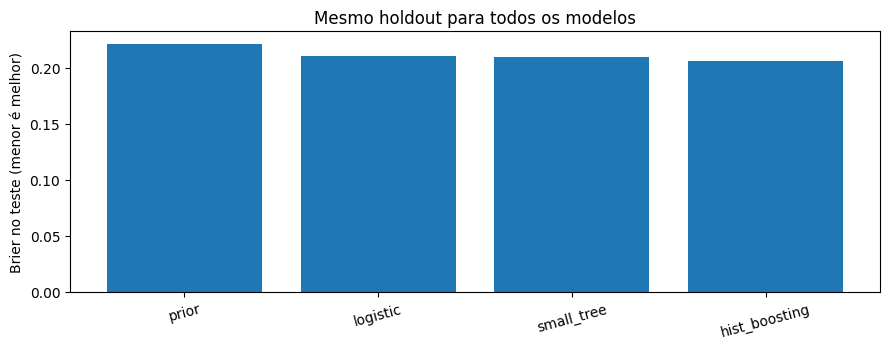

In [6]:
compare=s["model"]["comparisons"]
for name,r in compare.items():
 t=r["test"]
 print(f"{name:15s}: AUC={t['roc_auc']:.3f}, AP={t['average_precision']:.3f}, Brier={t['brier']:.4f}, lift@10={t['lift_top_decile']:.2f}x")
best=s["model"]["best_nontrivial_by_validation_brier"]
print("Escolhido pela VALIDAÇÃO:",best)
fig,ax=plt.subplots(figsize=(9,3.6))
ax.bar(list(compare),[compare[k]["test"]["brier"] for k in compare]);ax.set(ylabel="Brier no teste (menor é melhor)",title="Mesmo holdout para todos os modelos")
ax.tick_params(axis="x",rotation=15);plt.tight_layout();plt.show()

## 6. Calibração e desempenho em subpopulações do período de teste

O Brier é apenas uma medida agregada de qualidade probabilística. Bandas de confiabilidade permitem observar desvios entre previsão e incidência do evento. Ausência de desfechos em períodos posteriores impede afirmar estabilidade operacional.

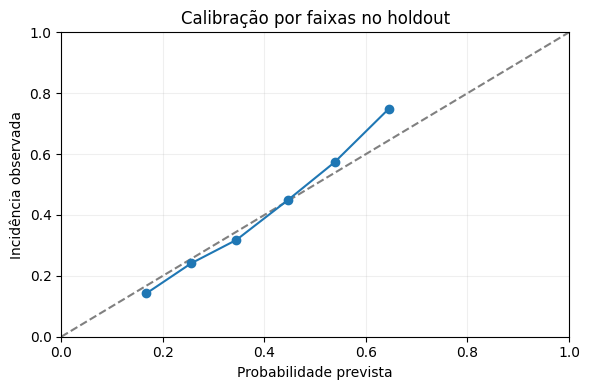


 chosen_test_by_month
2025-11 n=34,912 AUC=0.647 Brier=0.2094
2025-12 n=34,535 AUC=0.652 Brier=0.2036

 chosen_test_by_origin
LEGADO n=17,014 AUC=0.659 Brier=0.2046
SOLAR n=52,433 AUC=0.651 Brier=0.2071


In [7]:
b=s["model"]["comparisons"][best]["test_calibration"]["bins_at_least_100"]
fig,ax=plt.subplots(figsize=(6,4));ax.plot([0,1],[0,1],ls="--",color="gray")
ax.plot([r["predicted"] for r in b],[r["observed"] for r in b],"o-")
ax.set(xlabel="Probabilidade prevista",ylabel="Incidência observada",title="Calibração por faixas no holdout");ax.set_xlim(0,1);ax.set_ylim(0,1);ax.grid(alpha=.2);plt.tight_layout();plt.show()
for dim in ("chosen_test_by_month","chosen_test_by_origin"):
 print("\n",dim)
 for group,r in s["model"][dim].items():print(group,f"n={r['n']:,}",f"AUC={r['roc_auc']:.3f}",f"Brier={r['brier']:.4f}")

## 7. Sensibilidade à repetição e limites inferenciais

O mesmo cliente pode gerar registros diferentes. Comparamos todos os registros retidos à seleção do primeiro registro retido por ID. Não tratamos nenhuma dessas regras como identificação oficial de episódio.

In [8]:
first=s["first_retained_record_per_client_sensitivity"]
print("Todos os registros retidos:",f"{s['rates']['movement_given_retained']:.2%}")
print("Primeiro registro retido por ID:",f"{first['movement_rate']:.2%}",f"(n={first['n']:,})")

Todos os registros retidos: 34.71%
Primeiro registro retido por ID: 34.83% (n=235,462)


## 8. Implicações para decisões e próximos experimentos

1. **Personalização por mix inicial:** considerar a família elegível, não somente a presença de qualquer movimentação. Testar estratégias com aleatorização por carteira/origem e critérios financeiros.
2. **Movimentação com cancelamento parcial:** distinguir upgrade, substituição e saída de produtos; evitar tratar toda mudança como sucesso.
3. **Proteção do valor:** auditar tarifas, descontos e consolidação de faturas antes de mensurar receita preservada.
4. **Aceite real:** instrumentar exposição, decisão de oferta, proposta, concessão, tempo de atendimento e desfecho contratual; só então estimar aceitação e uplift.

**Fronteira de validade:** o estudo identifica associações observacionais na amostra e um modelo condicional em retidos. Não estima efeito causal, aceitação real ou receita incremental. Consulte `docs/study_report.md` para tabelas, definições e recomendações detalhadas.